In [62]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw

In [63]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [64]:
async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def run(left, right, T):
    try:
        await set_speed(left, right)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)

## Thymio stuff :

In [20]:
v = 300
T = 4 # [s]

await run(v, v, T)

Conversion ratio :  0.3201767676767677


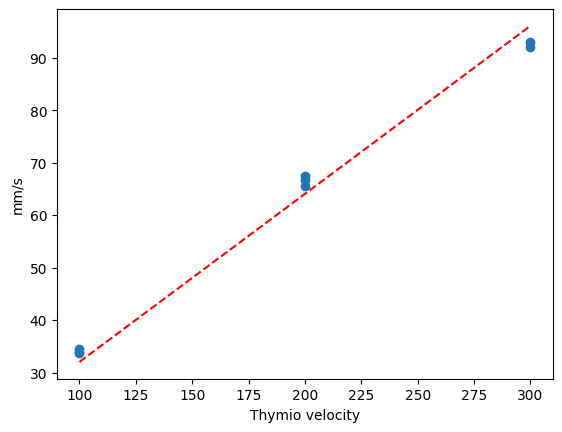

In [36]:
# assess speed conversion


logs = []
#logs.append([v, d]) [thymio, mm]

logs.append([100, 69/2])
logs.append([200, 135/2])
logs.append([300, 186/2])
logs.append([100, 102/3])
logs.append([200, 200/3])
# logs.append([300, 254/3])
logs.append([100, 135/4])
logs.append([200, 262/4])
logs.append([300, 368/4])


logs = np.array(logs)
v_thymio, v_real = logs[:, 0], logs[:, 1]
plt.scatter(logs[:, 0], logs[:, 1])
plt.xlabel("Thymio velocity")
plt.ylabel("mm/s")

rate = (v_thymio @ v_real) / (v_thymio @ v_thymio)
print("Conversion ratio : ", rate)


plt.plot([100, 300], [100*rate, 300*rate], c="red", linestyle="--")
plt.show()

In [43]:
# fix conversion ratio 

SPEED_TO_MM_S = 0.32

In [66]:
# estimate wheel base
     
s = 100
T = 2 # [s]

await run(-s, s, T)

In [ ]:
def get_wheel_base(s, T, N):
    angle = 2*np.pi * N
    return 2*SPEED_TO_MM_S*s*T / angle

In [ ]:
logs = [] # count turns done (with fraction)

#logs.append(get_wheel_base(s, T, ...))


In [ ]:
# wheel base 

WHEEL_BASE = None

In [ ]:
# estimate Q - Linear

v = None
T_lin = None
pred_along = SPEED_TO_MM_S * T_lin * v

await run(v, v, T_lin)
print(pred_along)

In [ ]:
along = [] # difference between measured and predicted

In [ ]:
# estimate Q - angular 

s = None
T_ang = None
pred_angle = 2 * SPEED_TO_MM_S * s * T_ang / WHEEL_BASE

await run(-s, s, T_ang)
print(pred_angle)

In [ ]:
e_theta = [] # difference between measured and predicted

In [ ]:
# estimate Q

q_xy = np.var(along, ddof=1) / 2 / T_lin
q_th = np.var(e_theta, ddof=1) / T_ang                                  
Q_RATE = np.diag([q_xy, q_xy, q_th])

## Camera stuff : 

In [ ]:
# measure variance of camera positions for several immobile positions 
# for the robot then take the mean of the variances

In [ ]:
def get_camera_pose():
    pass

In [ ]:
N = 10
xs, ys, thetas = [], [], []

while N > 0:
    [x, y, theta] = get_camera_pose()
    xs.append(x)
    ys.append(y)
    thetas.append(theta)
    N -= 1
    
xs, ys, thetas = np.array(xs), np.array(ys), np.array(thetas)

print("Var for x : ", np.var(xs), " mm^2")
print("Var for y : ", np.var(ys), " mm^2")
print("Var for th : ", np.var(thetas), " rad^2")

In [ ]:
xvar = []
yvar = []
thetavar = []

xvarmean, yvarmean, thetavarmean = np.mean(xvar), np.mean(yvar), np.mean(thetavar)

print("Var for x : ", np.mean(xvarmean), " mm^2")
print("Var for y : ", np.mean(yvarmean), " mm^2")
print("Var for theta : ", np.mean(thetavarmean), " rad^2")

R = np.diag([xvarmean, yvarmean, thetavarmean])

In [51]:
await node.unlock()

BrokenPipeError: [Errno 32] Broken pipe